# Data pipeline notebook

First few blocks are gonna be for playing around and analyzing data

Imports

In [1]:
import json, time
from pathlib import Path

import numpy as np
import stim                       # stabilizer-circuit simulator: makes the data
import pymatching                 # minimum-weight perfect matching: the baseline decoder
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import SVG, display

print("stim", stim.__version__, "| pymatching", pymatching.__version__, "| numpy", np.__version__)

stim 1.16.0 | pymatching 2.4.0 | numpy 2.5.3


Configurations

In [2]:
DISTANCE = 3
ROUNDS = 3
P = 0.005     # physical error rate applied to every noise channel
SEED = 1234   # fixed seed so the sampled outputs are reproducible

Building Circuit

In [3]:
circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    distance=DISTANCE,
    rounds=ROUNDS,
    after_clifford_depolarization=P,      # DEPOLARIZE1/2 after every H / CX
    before_round_data_depolarization=P,   # idle noise on data qubits each round
    before_measure_flip_probability=P,    # measurement flips
    after_reset_flip_probability=P,       # reset flips
)

# In Stim's layout, data qubits sit at odd (x, y) coordinates and measure qubits at even ones.
coords = circuit.get_final_qubit_coordinates()
data_qubits = sorted(q for q, (x, y) in coords.items() if x % 2 == 1)
measure_qubits = sorted(q for q, (x, y) in coords.items() if x % 2 == 0)
N_DATA, N_ANC = len(data_qubits), len(measure_qubits)

print(f"data qubits     ({N_DATA}): {data_qubits}")
print(f"measure qubits  ({N_ANC}): {measure_qubits}")
print(f"measurements / shot : {circuit.num_measurements}  (= {N_ANC} measure qubits x {ROUNDS} rounds + {N_DATA} final data)")
print(f"detectors           : {circuit.num_detectors}")
print(f"logical observables : {circuit.num_observables}")

data qubits     (9): [1, 3, 5, 8, 10, 12, 15, 17, 19]
measure qubits  (8): [2, 9, 11, 13, 14, 16, 18, 25]
measurements / shot : 33  (= 8 measure qubits x 3 rounds + 9 final data)
detectors           : 24
logical observables : 1


Print Circuit Design

In [4]:
print(circuit)

QUBIT_COORDS(1, 1) 1
QUBIT_COORDS(2, 0) 2
QUBIT_COORDS(3, 1) 3
QUBIT_COORDS(5, 1) 5
QUBIT_COORDS(1, 3) 8
QUBIT_COORDS(2, 2) 9
QUBIT_COORDS(3, 3) 10
QUBIT_COORDS(4, 2) 11
QUBIT_COORDS(5, 3) 12
QUBIT_COORDS(6, 2) 13
QUBIT_COORDS(0, 4) 14
QUBIT_COORDS(1, 5) 15
QUBIT_COORDS(2, 4) 16
QUBIT_COORDS(3, 5) 17
QUBIT_COORDS(4, 4) 18
QUBIT_COORDS(5, 5) 19
QUBIT_COORDS(4, 6) 25
R 1 3 5 8 10 12 15 17 19
X_ERROR(0.005) 1 3 5 8 10 12 15 17 19
R 2 9 11 13 14 16 18 25
X_ERROR(0.005) 2 9 11 13 14 16 18 25
TICK
DEPOLARIZE1(0.005) 1 3 5 8 10 12 15 17 19
H 2 11 16 25
DEPOLARIZE1(0.005) 2 11 16 25
TICK
CX 2 3 16 17 11 12 15 14 10 9 19 18
DEPOLARIZE2(0.005) 2 3 16 17 11 12 15 14 10 9 19 18
TICK
CX 2 1 16 15 11 10 8 14 3 9 12 18
DEPOLARIZE2(0.005) 2 1 16 15 11 10 8 14 3 9 12 18
TICK
CX 16 10 11 5 25 19 8 9 17 18 12 13
DEPOLARIZE2(0.005) 16 10 11 5 25 19 8 9 17 18 12 13
TICK
CX 16 8 11 3 25 17 1 9 10 18 5 13
DEPOLARIZE2(0.005) 16 8 11 3 25 17 1 9 10 18 5 13
TICK
H 2 11 16 25
DEPOLARIZE1(0.005) 2 11 16 25
TICK
X

Time slice betweeen ticks: Reset, Hadamar on X, 4 C-Not, Hadamar, measure, reset

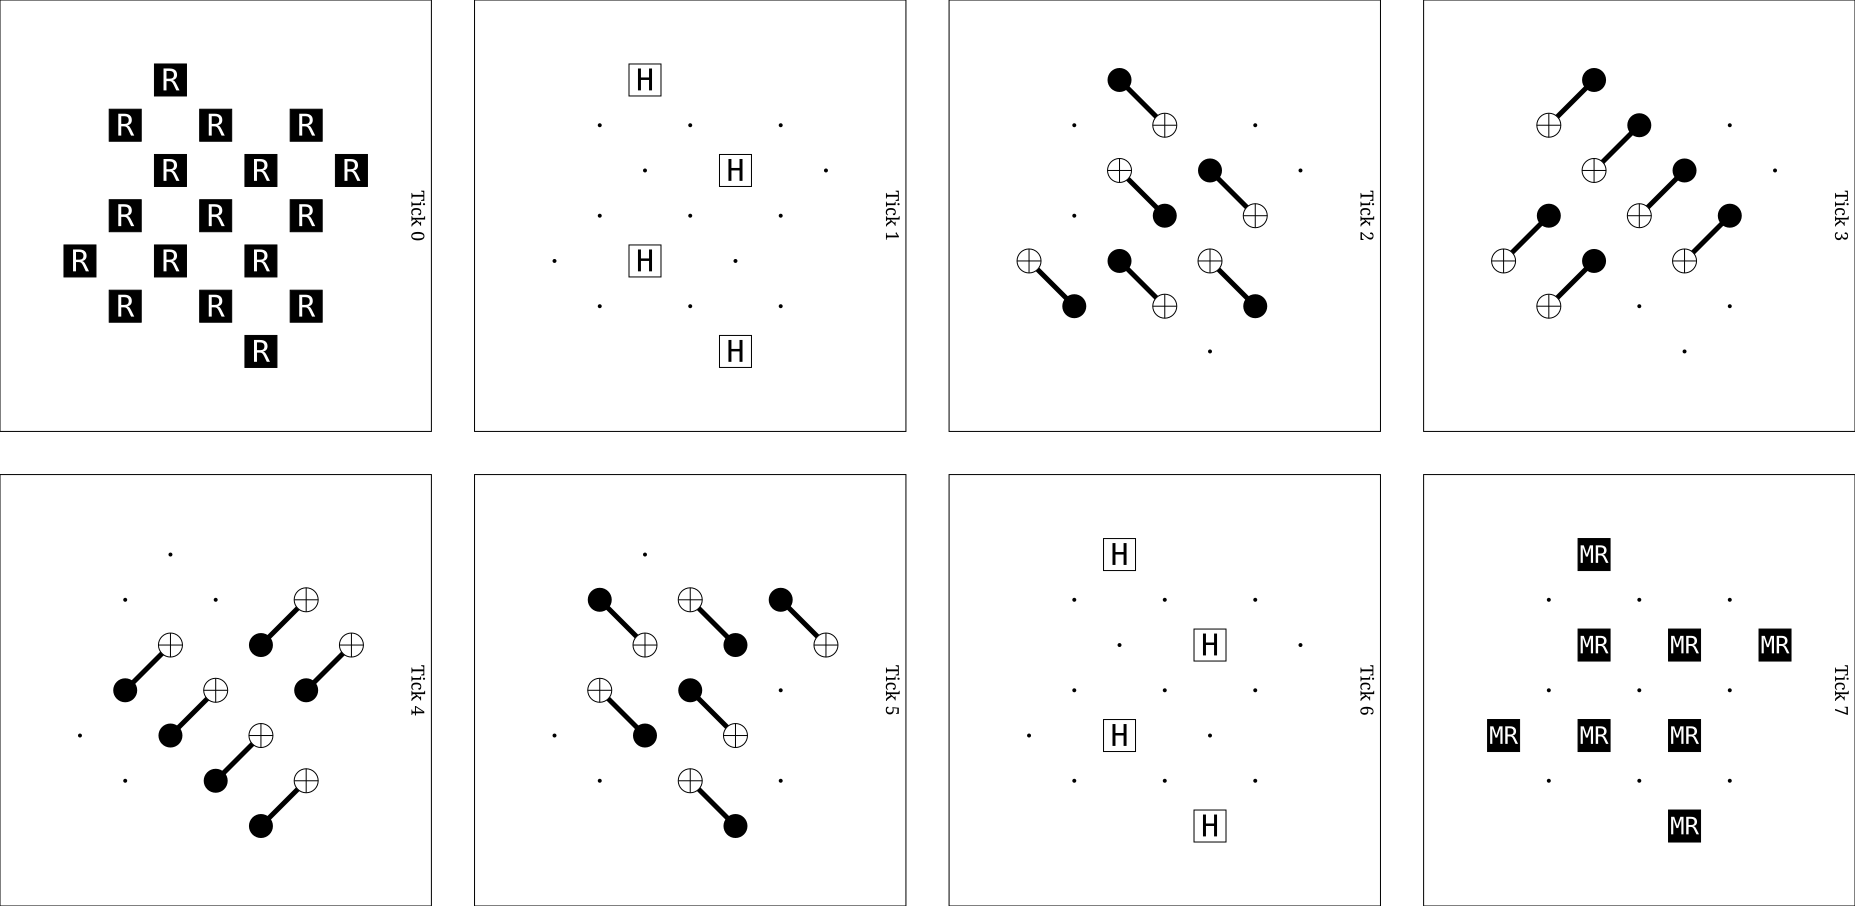

In [5]:
circuit.without_noise().diagram("timeslice-svg", tick = range(0,8), rows=2)

Shots and Rounds Raw measurements. X-bits are random in r0

In [6]:
meas = circuit.compile_sampler(seed=SEED).sample(shots=5).astype(np.uint8)
print("shape:", meas.shape, "\n")

bits = lambda a: "".join(map(str, a))
print(" " * 8 + "   ".join(f"round {r} " for r in range(ROUNDS)) + "   final data")
for s, row in enumerate(meas):
    rounds_str = "   ".join(bits(row[r * N_ANC:(r + 1) * N_ANC]) for r in range(ROUNDS))
    print(f"shot {s}: {rounds_str}   {bits(row[ROUNDS * N_ANC:])}")

shape: (5, 33) 

        round 0    round 1    round 2    final data
shot 0: 10000000   10000000   10000000   011111101
shot 1: 10100000   11100000   00100000   110100011
shot 2: 10000000   10000000   10000000   000000011
shot 3: 10100000   10100000   10100000   000110110
shot 4: 00100100   00100100   00100100   101011011


Detection Events : When a measurement changed

In [7]:
det_sampler = circuit.compile_detector_sampler(seed=SEED)
dets, obs = det_sampler.sample(shots=10, separate_observables=True)
print("detection events:", dets.shape, dets.dtype)
print("observable flips:", obs.shape, obs.dtype, "\n")

det_coords = circuit.get_detector_coordinates()
det_t = np.array([int(det_coords[i][2]) for i in range(circuit.num_detectors)])

print("         " + "   ".join(f"t={t} ({np.sum(det_t == t)})".ljust(max(8, np.sum(det_t == t))) for t in range(det_t.max() + 1)) + "   obs")
for s in range(len(dets)):
    groups = "   ".join(bits(dets[s, det_t == t].astype(np.uint8)).ljust(max(8, np.sum(det_t == t))) for t in range(det_t.max() + 1))
    print(f"shot {s}:  {groups}   {int(obs[s, 0])}")

detection events: (10, 24) bool
observable flips: (10, 1) bool 

         t=0 (4)    t=1 (8)    t=2 (8)    t=3 (4)    obs
shot 0:  0000       00000010   00000010   0000       0
shot 1:  0000       00000000   00000000   0000       0
shot 2:  0000       00000000   00100000   0000       0
shot 3:  0000       00000100   00000100   0000       0
shot 4:  0000       00000000   00000010   0010       0
shot 5:  0000       00000000   00000000   0000       0
shot 6:  0000       00000110   00000111   0010       0
shot 7:  0000       00000010   00000010   0000       0
shot 8:  0000       00000000   00000000   0000       0
shot 9:  0000       00000000   00000010   0010       0


Detector Error Model

In [8]:
dem = circuit.detector_error_model(decompose_errors=True)
print("error mechanisms:", dem.num_errors, "| detectors:", dem.num_detectors, "| observables:", dem.num_observables, "\n")
print("\n".join(str(dem).splitlines()[:20]))
print("...")

error mechanisms: 286 | detectors: 24 | observables: 1 

error(0.0096129529443096) D0
error(0.0096129529443096) D0 D1
error(0.01125854706194612) D0 D8
error(0.0096129529443096) D1 D2
error(0.01191150971274241) D1 D5
error(0.0006680041634191543) D1 D5 ^ D4
error(0.002001336305216213) D1 D8
error(0.0006680041634191543) D1 D8 ^ D4
error(0.0203253599098319) D1 L0
error(0.02000461382778225) D2
error(0.01092240000000015) D2 D3
error(0.002666666666666795) D2 D3 ^ D6
error(0.002998998440543733) D2 D5
error(0.001001671498398811) D2 D5 ^ D6
error(0.0006680041634191543) D2 D5 ^ D6 D9
error(0.0003341137136832484) D2 D5 ^ D9
error(0.0003341137136832484) D2 D5 ^ D9 ^ D6
error(0.0003341137136832484) D2 D8
error(0.0003341137136832484) D2 D8 ^ D6
error(0.0003341137136832484) D2 D8 ^ D9
...


MWPM example

In [9]:
matcher = pymatching.Matching.from_detector_error_model(dem)

N_SHOTS = 100_000
dets, obs = circuit.compile_detector_sampler(seed=SEED).sample(N_SHOTS, separate_observables=True)
pred = matcher.decode_batch(dets)

mwpm_errors = np.sum(np.any(pred != obs, axis=1))
print(f"shots                      : {N_SHOTS:,}")
print(f"no decoding  logical error : {np.mean(obs[:, 0]):.4%}")
print(f"MWPM         logical error : {mwpm_errors / N_SHOTS:.4%}  ({mwpm_errors} failures)")

shots                      : 100,000
no decoding  logical error : 10.2820%
MWPM         logical error : 1.6190%  (1619 failures)
